# EDA: Bank Marketing (UCI id=222) — Левин

**Кейс.** Португальский банк обзванивал клиентов (2008–2010) и предлагал срочный депозит. Цель `y` — согласился ли клиент (`yes`/`no`).
**Зачем EDA.** Понять данные до построения предиктора: качество, смысл признаков, утечки, закономерности, идеи для фичей.

**План:**
0. **Разведка:** просто смотрим на данные глазами — что в таблице, какие типы, распределения, выбросы и странности
1. Оптимизация памяти (уже понимая, с чем имеем дело)
2. Качество данных: пропуски, дубликаты, выбросы, «скрытые» структуры
3. Целевая переменная
4. Числовые и категориальные признаки vs. таргет
5. Проверка гипотез: конверсия по группам
6. Идеи для фичей и итоговые выводы

## Импорты и настройки

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from ucimlrepo import fetch_ucirepo

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4.5)
pd.set_option('display.max_columns', 50, 'display.width', 140)

## 0. Разведка: что вообще за данные
Прежде чем что-то оптимизировать и проверять, просто посмотрим на таблицу глазами. Вопросы этого блока:
*сколько данных? какие столбцы и какого типа? как они распределены? что выглядит странно?*
Выводы — в конце блока, подробный анализ и гипотезы — дальше.

### 0.1 Загружаем и смотрим на первые строки

In [2]:
bm = fetch_ucirepo(id=222)
df_raw = pd.concat([bm.data.features, bm.data.targets], axis=1)   # признаки + таргет в одну таблицу
print('Строк, столбцов:', df_raw.shape)
df_raw.head(10)

Строк, столбцов: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
8,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
9,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no


Для справки — описание столбцов от авторов датасета (чтобы понимать смысл):

In [3]:
bm.variables[['name','role','type','description','missing_values']].style.set_properties(subset=['description'], **{'white-space':'pre-wrap'})

,name,role,type,description,missing_values
0,age,Feature,Integer,nan,no
1,job,Feature,Categorical,"type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')",no
2,marital,Feature,Categorical,"marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)",no
3,education,Feature,Categorical,"(categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')",no
4,default,Feature,Binary,has credit in default?,no
5,balance,Feature,Integer,average yearly balance,no
6,housing,Feature,Binary,has housing loan?,no
7,loan,Feature,Binary,has personal loan?,no
8,contact,Feature,Categorical,"contact communication type (categorical: 'cellular','telephone')",yes
9,day_of_week,Feature,Date,last contact day of the week,no


**Что видно по первым строкам:** это клиенты банка (возраст, работа, семейное положение, баланс на счёте, есть ли кредиты) плюс данные об **обзвоне** (канал связи, месяц, длительность звонка, сколько раз звонили, что было в прошлой кампании). Последний столбец `y` — согласился ли клиент на депозит.
Сразу бросаются в глаза `NaN` в `contact` / `poutcome` и значения `pdays = -1` — вернёмся к ним.

### 0.2 Типы данных и размер

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [5]:
# Делим столбцы на числовые и категориальные и смотрим, сколько в каждом уникальных значений
num_cols = df_raw.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df_raw.columns if c not in num_cols]
print('Числовые       :', num_cols)
print('Категориальные :', cat_cols)
df_raw.nunique().sort_values().to_frame('уникальных значений').T

Числовые       : ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']
Категориальные : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


,contact,loan,housing,default,y,marital,poutcome,education,job,month,day_of_week,previous,campaign,age,pdays,duration,balance
уникальных значений,2,2,2,2,2,3,3,3,11,12,31,41,48,77,559,1573,7168


**Вывод:** 45 211 строк × 17 столбцов; 7 числовых и 10 текстовых. Среди текстовых большинство бинарные (`default`, `housing`, `loan`, `y`) или с малым числом уровней — ложатся в `category`. Пропуски есть только в 4 столбцах (подробнее в п. 2.1). Заметим, что `day_of_week` имеет **31** уникальное значение — для «дня недели» странно, разберёмся в п. 2.2.

### 0.3 Числовые признаки: статистика и распределения

In [6]:
df_raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(1)

,count,mean,std,min,1%,25%,50%,75%,99%,max
age,45211.0,40.9,10.6,18.0,23.0,33.0,39.0,48.0,71.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,-627.0,72.0,448.0,1428.0,13164.9,102127.0
day_of_week,45211.0,15.8,8.3,1.0,2.0,8.0,16.0,21.0,31.0,31.0
duration,45211.0,258.2,257.5,0.0,11.0,103.0,180.0,319.0,1269.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,1.0,2.0,3.0,16.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,-1.0,370.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,0.0,8.9,275.0


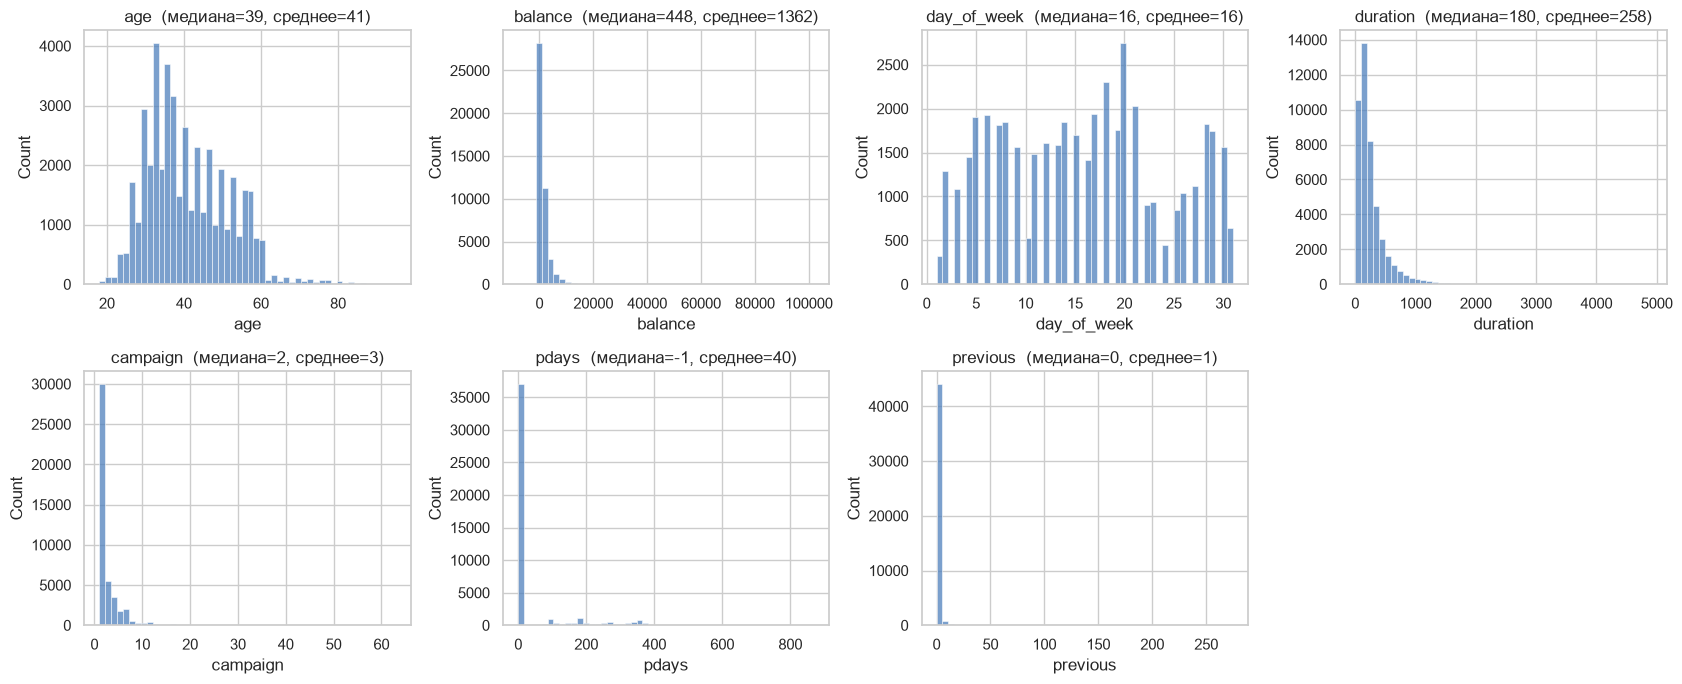

In [7]:
fig, axs = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axs.ravel(), num_cols):
    sns.histplot(df_raw[c], bins=50, ax=ax, color='#4f81bd')
    ax.set_title(f'{c}  (медиана={df_raw[c].median():.0f}, среднее={df_raw[c].mean():.0f})')
axs.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

**Что видно:**
- `age`: почти колоколообразный, основная масса 30–50 лет, диапазон 18–95 — разумно.
- `balance`, `duration`, `campaign`, `previous`, `pdays`: **сильно скошены вправо** — среднее заметно больше медианы, максимум на порядки выше 99-го перцентиля. Гистограммы «схлопнуты» в левый край из-за хвостов.
- `pdays`: огромный пик на `-1` и длинный хвост до 871.
- `day_of_week`: значения 1–31, примерно равномерно — похоже на день месяца.

Чтобы увидеть форму «тела» распределений, а не только хвосты, посмотрим то же в логарифмической шкале и на boxplot:

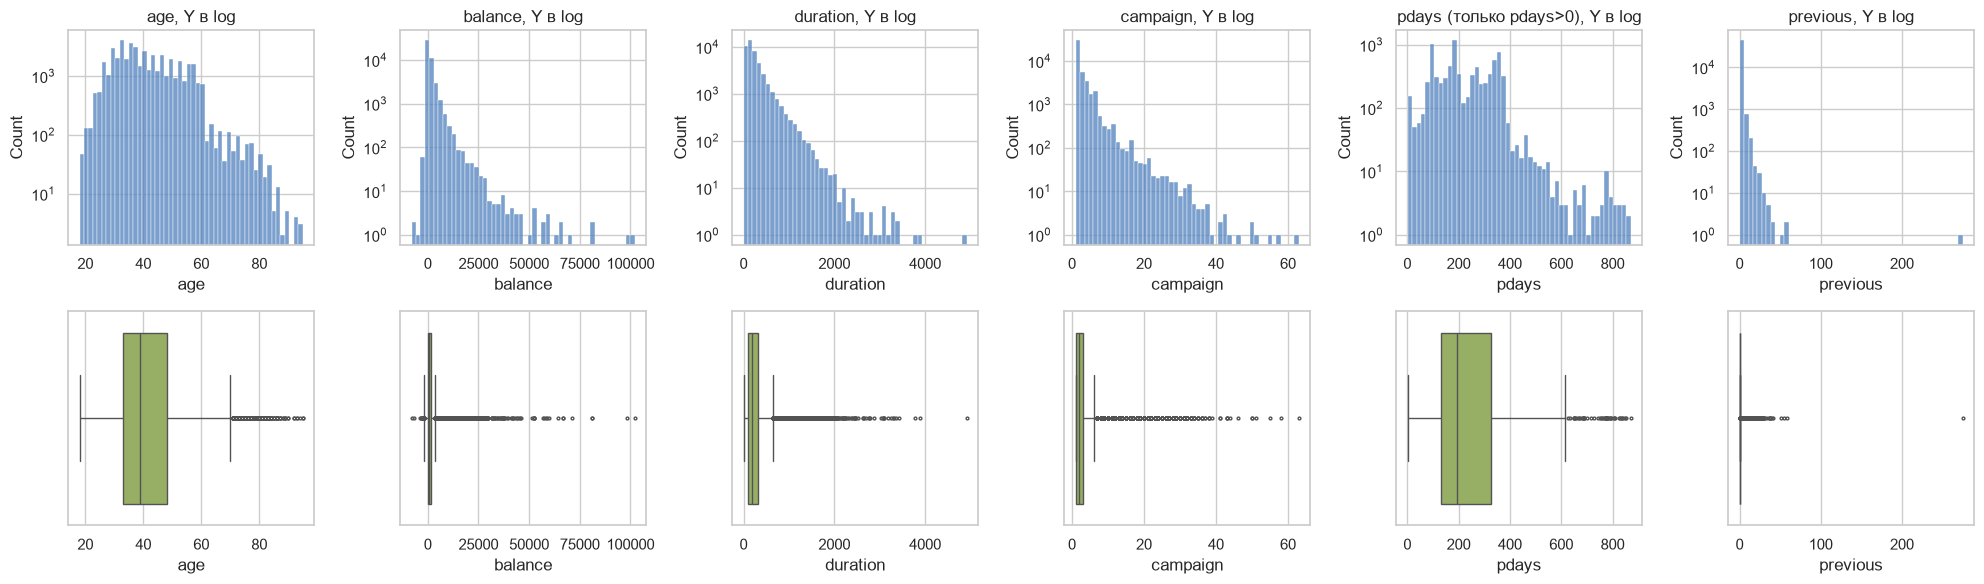

In [8]:
cols = ['age','balance','duration','campaign','pdays','previous']
fig, axs = plt.subplots(2, 6, figsize=(20, 6))
for i, c in enumerate(cols):
    x = df_raw[c] if c != 'pdays' else df_raw.loc[df_raw.pdays > 0, 'pdays']
    sns.histplot(x, bins=50, ax=axs[0, i], color='#4f81bd'); axs[0, i].set_yscale('log')
    axs[0, i].set_title(c + (' (только pdays>0)' if c == 'pdays' else '') + ', Y в log')
    sns.boxplot(x=x, ax=axs[1, i], color='#9bbb59', fliersize=2)
plt.tight_layout(); plt.show()

### 0.4 Категориальные признаки: какие значения и как часто

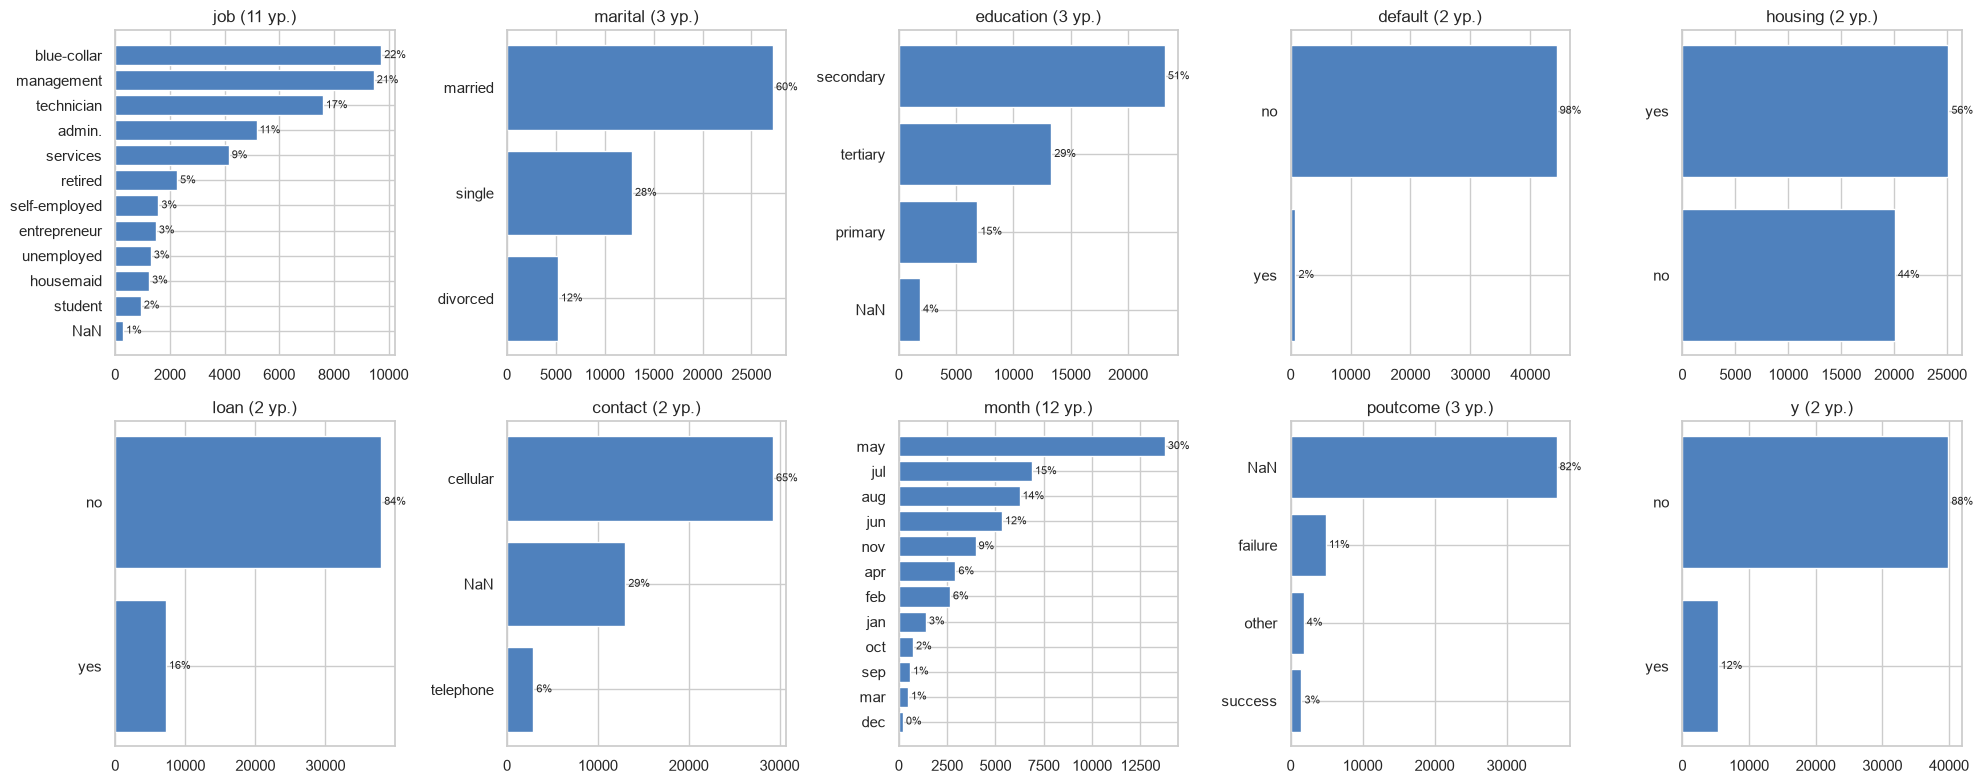

In [9]:
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for ax, c in zip(axs.ravel(), cat_cols):
    vc = df_raw[c].fillna('NaN').value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color='#4f81bd')
    for i, v in enumerate(vc.values[::-1]): ax.text(v, i, f' {v/len(df_raw):.0%}', va='center', fontsize=8)
    ax.set_title(f'{c} ({df_raw[c].nunique()} ур.)')
plt.tight_layout(); plt.show()

**Что видно:**
- `job`: 11 профессий; лидеры — `blue-collar`, `management`, `technician`; `student`, `housemaid`, `unemployed` — редкие (≈2–3%).
- `marital`: большинство женаты (≈60%).
- `education`: преобладает `secondary`; есть NaN (≈4%).
- `default`: почти все `no` (98%); `housing` ≈ 56% `yes`; `loan` ≈ 16% `yes`.
- `contact`: заметная доля NaN (≈29%) — вряд ли случайная (проверим в H2).
- `month`: очень неравномерно — май ≈ 30% всех строк, зимой данных мало.
- `poutcome`: ≈82% NaN — самый «дырявый» столбец.
- `y`: перекос, «no» ≈ 88%.

### 0.5 Первые странности и аномалии
Пройдёмся по подозрительным местам и просто посчитаем, сколько там строк.

In [10]:
checks = {
    'age >= 80':                       (df_raw.age >= 80).sum(),
    'balance < 0 (минус на счёте)':    (df_raw.balance < 0).sum(),
    'balance > 50 000':                (df_raw.balance > 50_000).sum(),
    'duration == 0 (звонок 0 сек)':    (df_raw.duration == 0).sum(),
    'duration < 10 сек':               (df_raw.duration < 10).sum(),
    'duration > 3600 сек (час)':       (df_raw.duration > 3600).sum(),
    'campaign > 20 звонков':           (df_raw.campaign > 20).sum(),
    'previous > 20':                   (df_raw.previous > 20).sum(),
    'pdays == -1 (ранее не звонили)':  (df_raw.pdays == -1).sum(),
    'pdays > 400':                     (df_raw.pdays > 400).sum(),
    'default == yes':                  (df_raw.default == 'yes').sum(),
}
pd.Series(checks, name='строк').to_frame().assign(доля=lambda d: (d['строк'] / len(df_raw)).map('{:.2%}'.format))

,строк,доля
age >= 80,130,0.29%
balance < 0 (минус на счёте),3766,8.33%
balance > 50 000,18,0.04%
duration == 0 (звонок 0 сек),3,0.01%
duration < 10 сек,342,0.76%
duration > 3600 сек (час),3,0.01%
campaign > 20 звонков,244,0.54%
previous > 20,55,0.12%
pdays == -1 (ранее не звонили),36954,81.74%
pdays > 400,234,0.52%


In [11]:
# Глазами на самые «крайние» строки
display(df_raw.nlargest(3, 'balance')); display(df_raw.nlargest(3, 'previous')); display(df_raw.nlargest(3, 'campaign')); display(df_raw[df_raw.duration == 0])

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
39989,51,management,single,tertiary,no,102127,no,no,cellular,3,jun,90,1,-1,0,NaN,no
26227,59,management,married,tertiary,no,98417,no,no,telephone,20,nov,145,5,-1,0,NaN,no
42558,84,retired,married,secondary,no,81204,no,no,telephone,28,dec,679,1,313,2,other,yes


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
29182,40,management,married,tertiary,no,543,yes,no,cellular,2,feb,349,2,262,275,other,no
38326,46,blue-collar,married,primary,no,1085,yes,yes,cellular,15,may,523,2,353,58,other,yes
44089,37,technician,married,secondary,no,432,yes,no,cellular,6,jul,386,3,776,55,failure,yes


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
4330,45,management,married,NaN,no,9051,yes,no,NaN,19,may,124,63,-1,0,NaN,no
11914,24,technician,single,primary,no,126,yes,no,NaN,20,jun,10,58,-1,0,NaN,no
5073,35,technician,married,secondary,no,432,yes,no,NaN,21,may,1094,55,-1,0,NaN,no


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
6424,53,management,married,primary,no,351,yes,no,NaN,27,may,0,4,-1,0,NaN,no
22937,35,technician,married,secondary,no,5535,no,no,cellular,26,aug,0,15,-1,0,NaN,no
36425,31,entrepreneur,married,secondary,no,162,yes,yes,cellular,11,may,0,2,-1,0,NaN,no


### Итог разведки — что поняли и что проверим дальше
| Наблюдение | Куда разбираем |
|---|---|
| Дублей нет, но `NaN` есть в 4 столбцах; в `contact` (29%) и `poutcome` (82%) — много | п. 2.1, гипотезы H1, H2 |
| `pdays = -1` у 82% — не число, а маркер «ранее не звонили» | H1 |
| `day_of_week` принимает значения 1–31 — скорее день месяца | п. 2.2 |
| Все числовые, кроме `age`, скошены с тяжёлыми хвостами (`balance` до 102 тыс., `previous` до 275, `campaign` до 63) | п. 2.3 |
| Отдельные странности: звонки по 0 сек, «одиночные» выбросы (`previous=275`), ≈8% отрицательных балансов | п. 2.3 — решаем, что делать |
| Перекос по `month` (май ≈ 30%) и по таргету (≈12% «да») | п. 3, H4 |

Теперь, когда ясно, с чем имеем дело, **оптимизируем память**, а затем перейдём к детальному анализу.

## 1. Оптимизация памяти
**Зачем:** датасет небольшой, но привычка важна — на больших выборках `object`/`int64` раздувают память. После разведки мы знаем, что у текстовых столбцов мало уровней (→ `category`), а числа помещаются в маленькие целые типы.

In [12]:
def optimize(df):
    df = df.copy()
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_integer_dtype(s):
            df[c] = pd.to_numeric(s, downcast='integer')
        elif pd.api.types.is_float_dtype(s):
            df[c] = pd.to_numeric(s, downcast='float')
        else:
            df[c] = s.astype('category')
    return df

before = df_raw.memory_usage(deep=True).sum() / 1024**2
df = optimize(df_raw)
assert (df[num_cols].values == df_raw[num_cols].values).all()   # числа не обрезались при уменьшении типа
after = df.memory_usage(deep=True).sum() / 1024**2
print(f'Память (deep): {before:.2f} МБ -> {after:.2f} МБ  (−{100*(1-after/before):.0f}%)')  # deep=True считает реальный размер строк
df.dtypes.to_frame('dtype').T

Память (deep): 24.56 МБ -> 0.99 МБ  (−96%)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
dtype,int8,category,category,category,category,int32,category,category,category,int8,category,int16,int8,int16,int16,category,category


## 2. Качество данных
### 2.1 Пропуски и дубликаты
**Зачем:** в UCI-описании пропусков «нет», но в данных `NaN` есть. Важно понять, это *случайная потеря* или *осмысленное отсутствие*.

In [13]:
print('Дубликатов строк:', df.duplicated().sum())
miss = df.isna().agg(['sum','mean']).T.rename(columns={'sum':'n','mean':'share'})
miss[miss.n>0].sort_values('share', ascending=False).style.format({'share':'{:.1%}'})

Дубликатов строк: 0


,n,share
poutcome,36959.000000,81.7%
contact,13020.000000,28.8%
education,1857.000000,4.1%
job,288.000000,0.6%


**Гипотеза H1: пропуски в `poutcome` — не потеря, а «клиента раньше не обзванивали».**
Проверяем связь `poutcome=NaN` ↔ `pdays=-1` ↔ `previous=0`.

In [14]:
print(pd.crosstab(df.pdays == -1, df.previous == 0, rownames=['pdays==-1'], colnames=['previous==0']))
print()
print(pd.crosstab(df.poutcome.isna(), df.pdays == -1, rownames=['poutcome NaN'], colnames=['pdays==-1']))

previous==0  False  True 
pdays==-1                
False         8257      0
True             0  36954

pdays==-1     False  True 
poutcome NaN              
False          8252      0
True              5  36954


**Вывод H1: подтверждена.** `pdays=-1` ⇔ `previous=0` (полное совпадение). `poutcome=NaN` почти совпадает с ними (5 строк — исключения: предыдущий контакт был, но исход не записан).
Значит `poutcome=NaN` — это категория **«нет предыдущей кампании»** (82% клиентов), а не пропуск. Для модели: заполнять как отдельную категорию `no_prev`, а не импьютить модой. Заодно `pdays=-1` — это **маркер**, а не число: подавать его в линейную модель как есть нельзя (будет «близко к 0 дней»).

**Гипотеза H2: пропуски `contact` — не случайны, а привязаны ко времени.**

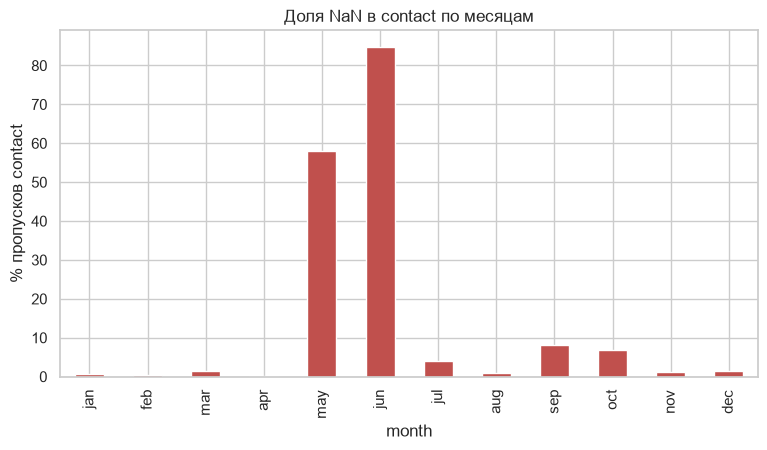

contact
False    0.147836
True     0.040707
Name: conv. rate, dtype: float64


In [15]:
tab = pd.crosstab(df.month, df.contact.isna(), normalize='index')[True].reindex(
    ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'])
ax = (tab*100).plot.bar(color='#c0504d'); ax.set_ylabel('% пропусков contact'); ax.set_title('Доля NaN в contact по месяцам')
plt.show()
print(df.groupby(df.contact.isna(), observed=True).y.apply(lambda s: (s=='yes').mean()).rename('conv. rate'))

**Вывод H2 (предварительный):** `contact` пропущен почти исключительно в **мае и июне**, а конверсия у таких строк ~4% против ~15% у остальных. Но месяц и год перемешаны (см. п. 2.2), поэтому эту связь мы ещё уточним в **H2b — после восстановления года**: возможно, дело не в «контакте», а во времени.

Остальные пропуски (`education` 4%, `job` 0.6%) — небольшие; тоже оставляем как категорию `unknown`: у `education=NaN` конверсия отличается от остальных (см. раздел 4), так что сам факт пропуска информативен.

### 2.2 «Скрытая» структура времени
**Зачем:** в данных нет года, а `day_of_week` по описанию — «день недели». Проверим, что это на самом деле. Если данные упорядочены хронологически, то это (а) позволяет восстановить дату, (б) **определяет, как делить на train/test** — случайный split даст оптимистичную оценку.

In [16]:
print('day_of_week: min/max =', df.day_of_week.min(), df.day_of_week.max(), '| уникальных:', df.day_of_week.nunique())
months = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
mnum = df.month.astype(str).map({m:i+1 for i,m in enumerate(months)})
# новый год наступает, когда номер месяца в потоке строк «сбрасывается» назад
year = 2008 + (mnum.diff().fillna(0) < 0).cumsum()
print(year.value_counts().sort_index())

day_of_week: min/max = 1 31 | уникальных: 31
month
2008    27729
2009    14862
2010     2620
Name: count, dtype: int64


**Вывод:** `day_of_week` принимает значения 1–31 → это **день месяца**, а не день недели (название в UCI вводит в заблуждение). Строки идут в хронологическом порядке, и «сброс» номера месяца даёт ровно 3 года: 2008, 2009, 2010 — что соответствует описанию датасета (май 2008 – ноябрь 2010). Восстановим дату и проверим конверсию по времени.

Невалидных дат (напр. 31 июня): 0


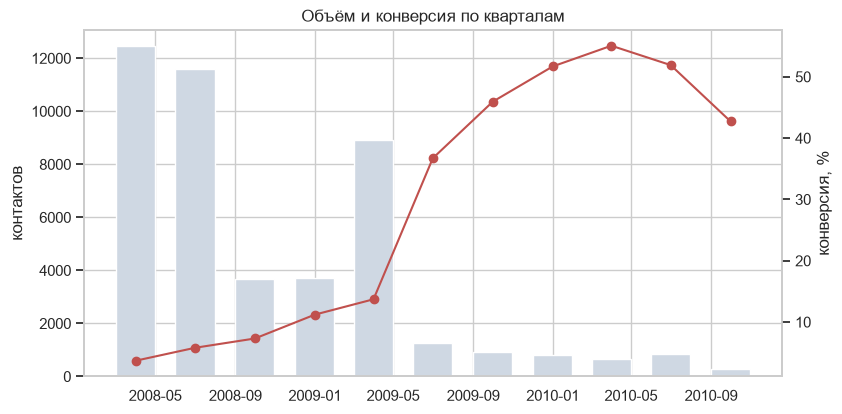

In [17]:
df['year'] = year.astype('int16'); df['month_num'] = mnum.astype('int8'); df['day'] = df.day_of_week.astype('int8')
df['date'] = pd.to_datetime(dict(year=df.year, month=df.month_num, day=df.day), errors='coerce')
print('Невалидных дат (напр. 31 июня):', df.date.isna().sum())
df['target'] = (df.y == 'yes').astype('int8')
m = df.dropna(subset=['date']).set_index('date').target.resample('QS').agg(['mean','size'])
fig, ax = plt.subplots(); ax.bar(m.index, m['size'], width=60, color='#cfd8e3', label='кол-во контактов')
ax2 = ax.twinx(); ax2.plot(m.index, m['mean']*100, 'o-', color='#c0504d'); ax2.set_ylabel('конверсия, %'); ax.set_ylabel('контактов')
ax.set_title('Объём и конверсия по кварталам'); ax2.grid(False); plt.show()

**Вывод:** конверсия **радикально нестабильна во времени**: по годам ≈ **5% (2008, 27.7 тыс. контактов) → 17% (2009, 14.9 тыс.) → 52% (2010, 2.6 тыс.)**. В 2008 был массовый обзвон с низкой отдачей, дальше банк звонил всё меньшему и более целевому кругу. Это самая большая «скрытая» закономерность в данных и главный риск для модели: **валидироваться надо по времени** (train — раньше, test — позже), иначе оценка качества будет завышена, а признаки вроде месяца будут «подсматривать» год (см. H4).

### H2b. Пропуски `contact` — это начало массового обзвона 2008 года?
**Идея:** возможно, пропуски появились в первые месяцы массового обзвона (когда конверсия была низкой), а потом при точечных обзвонах качество данных и конверсия выросли. Проверяем: как распределены `NaN` по годам и сохраняется ли разница в конверсии *внутри* одного года.

In [18]:
df['contact_na'] = df.contact.isna()
by_year = df.groupby('year').contact_na.agg(share_nan='mean', n_nan='sum', n_rows='size')
display(by_year.style.format({'share_nan':'{:.1%}'}))
print('Доля ВСЕХ пропусков contact, приходящаяся на 2008 год: {:.1%}'.format(df.loc[df.contact_na,'year'].eq(2008).mean()))
print('Доля NaN в 2008 по месяцам (только месяцы с NaN):')
display(df[df.year==2008].groupby('month', observed=True).contact_na.agg(['mean','sum','size']).query('sum>0').round(3))
# конверсия NaN vs не-NaN ВНУТРИ каждого года
display((df.groupby(['year','contact_na']).target.agg(['mean','size']).unstack()
         .rename(columns={False:'contact известен', True:'contact=NaN'}).round(3)))

,share_nan,n_nan,n_rows
year,,,
2008,46.0%,12765,27729
2009,0.0%,4,14862
2010,9.6%,251,2620


Доля ВСЕХ пропусков contact, приходящаяся на 2008 год: 98.0%
Доля NaN в 2008 по месяцам (только месяцы с NaN):


,mean,sum,size
month,,,
aug,0.002,10,5215
dec,0.231,3,13
jul,0.037,235,6380
jun,1.000,4486,4486
may,1.000,7957,7957
nov,0.013,48,3598
oct,0.325,26,80


mean                         size            
contact_na contact известен contact=NaN contact известен contact=NaN
year                                                                
2008                  0.060       0.039            14964       12765
2009                  0.170       0.750            14858           4
2010                  0.558       0.120             2369         251

**Вывод H2b: гипотеза подтверждена — с важной поправкой.**
- **98% всех пропусков `contact` (12 765 из 13 020) — это 2008 год**, и там это **не «примерно половина», а сплошной блок: май и июнь 2008 — 100% строк без `contact`** (≈12.4 тыс. контактов — первые месяцы кампании). В 2009 пропусков почти нет (4 строки), в 2010 — ≈10% (251 строка, разрозненно).
- То есть это не «слабый канал связи», а **период, когда канал связи не записывали** (или такие данные потеряны) — вместе с массовым обзвоном с низкой отдачей (конверсия 2008 ≈ 5%).
- **Исходные «4% против 15%» сильно завышали связь:** внутри 2008 разница намного меньше — **3.9% (NaN) против 6.0% (известен)**. Основная часть разницы — просто «год»: NaN почти все из дешёвого 2008-го.
- В 2010 картина обратная и своеобразная: NaN-строки там конвертятся хуже (12% против 56%), но их всего 251 — выводов не делаем, возможно, другая подвыборка.

**Практический вывод:** `contact_unknown` — это в первую очередь **прокси периода (май–июнь 2008)**, а не самостоятельный сигнал. На временной валидации (train = ранние годы, test = поздние) этот флаг почти не будет работать — в test его просто нет. Не стоит полагаться на него как на «важную фичу» и интерпретировать как «клиент без контакта плохо конвертируется».

### 2.3 Выбросы и странные значения
**Зачем:** решаем, что делать с хвостами (клиппинг, лог-преобразование, робастные модели).

In [19]:
num = ['age','balance','duration','campaign','pdays','previous']
display(df[num].describe(percentiles=[.01,.5,.99]).T.round(1))
print('Клиентов с отрицательным balance: {:.1%}'.format((df.balance<0).mean()))
print('previous > 20:', (df.previous>20).sum(), '| campaign > 20:', (df.campaign>20).sum())

,count,mean,std,min,1%,50%,99%,max
age,45211.0,40.9,10.6,18.0,23.0,39.0,71.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,-627.0,448.0,13164.9,102127.0
duration,45211.0,258.2,257.5,0.0,11.0,180.0,1269.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,16.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,370.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,8.9,275.0


Клиентов с отрицательным balance: 8.3%
previous > 20: 55 | campaign > 20: 244


In [20]:
# Доля значений за «усами» boxplot (правило 1.5*IQR) и во что превращается хвост после клиппинга по 99-му перцентилю
rows = []
for c in ['age','balance','duration','campaign','previous']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    out = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).mean()
    rows.append((c, f'{out:.1%}', df[c].quantile(.99), df[c].max(), f'{df[c].skew():.1f} -> {np.log1p(df[c].clip(lower=0)).skew():.1f}'))
pd.DataFrame(rows, columns=['признак','за усами IQR','p99','max','skew до -> после log1p']).set_index('признак')

,за усами IQR,p99,max,skew до -> после log1p
признак,,,,
age,1.1%,71.0,95,0.7 -> 0.1
balance,10.5%,13164.9,102127,8.4 -> -0.9
duration,7.2%,1269.0,4918,3.1 -> -0.5
campaign,6.8%,16.0,63,4.9 -> 1.3
previous,18.3%,8.9,275,41.8 -> 2.5


**Вывод:** (гистограммы см. в п. 0.3) все числовые признаки сильно скошены вправо с длинными хвостами: `balance` до 102 127 (и 8% отрицательных), `campaign` до 63, `previous` до 275 (выброс-одиночка), `duration` до 4918 сек. Оговорка по таблице выше: у `previous` «18% выбросов» по IQR — артефакт метода (82% значений нули, IQR вырождается), реальные выбросы там единичные. Звонков длиной 0 сек всего 3 (все с `y=no`) — это шум, а не системная проблема. Эти значения реальные, а не ошибочные — удалять не нужно, но для линейных моделей: `log1p`/клиппинг по 99-му перцентилю; для деревьев — можно оставить как есть.

## 3. Целевая переменная
**Зачем:** дисбаланс определяет метрики (accuracy бесполезна) и способ валидации.

In [21]:
vc = df.y.value_counts(); print(vc.to_string()); print(f'Доля yes: {df.target.mean():.2%}')
print(f'Тривиальный классификатор «всем no» даёт accuracy = {1-df.target.mean():.2%}')

y
no     39922
yes     5289
Доля yes: 11.70%
Тривиальный классификатор «всем no» даёт accuracy = 88.30%


**Вывод:** классы несбалансированы — `yes` ≈ **11.7%** (1 к ~7.5). Accuracy ≈ 88% достигается, если просто всем говорить «нет», поэтому оцениваем **ROC-AUC / PR-AUC / F1 / lift**, используем стратифицированные фолды (или временной split) и при необходимости `class_weight` / подбор порога. Бизнес-смысл: банку важен не «угадать всех», а ранжировать клиентов так, чтобы звонить в первую очередь тем, у кого вероятность выше (lift@k).

## 4. Признаки против таргета
**Зачем:** увидеть, какие признаки дают сигнал и в какой форме (монотонно, U-образно, порогово) — это определяет, нужны ли бинирование и взаимодействия.

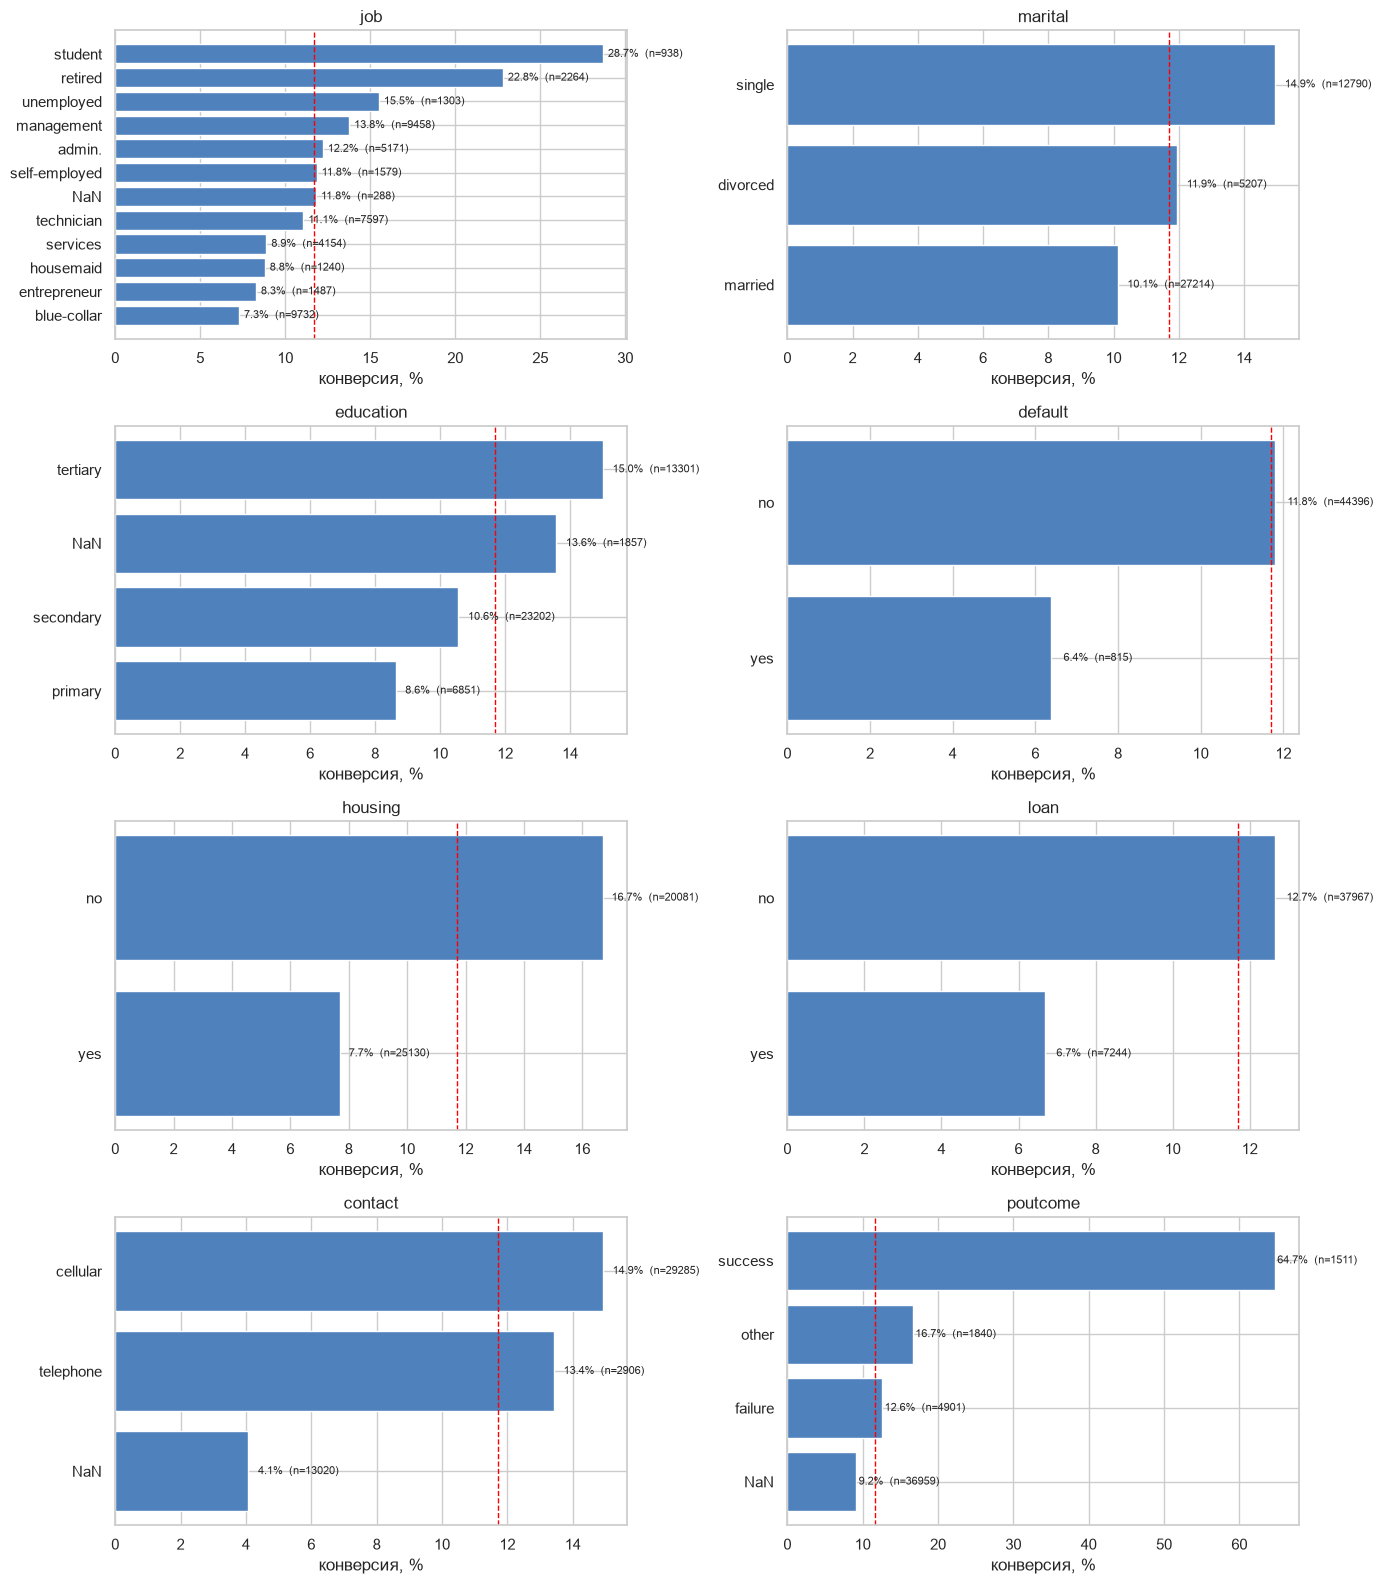

In [22]:
def rate_plot(col, order=None, ax=None, title=None, min_n=0):
    g = df.groupby(df[col].astype('object').fillna('NaN'), observed=True).target.agg(['mean','size'])
    g = g[g['size']>=min_n]
    g = g.loc[order] if order else g.sort_values('mean')
    ax = ax or plt.gca()
    ax.barh(g.index.astype(str), g['mean']*100, color='#4f81bd')
    for i,(r,n) in enumerate(zip(g['mean'], g['size'])): ax.text(r*100+.3, i, f'{r:.1%}  (n={n})', va='center', fontsize=8)
    ax.axvline(df.target.mean()*100, color='red', ls='--', lw=1); ax.set_title(title or col); ax.set_xlabel('конверсия, %')

cats = ['job','marital','education','default','housing','loan','contact','poutcome']
fig, axs = plt.subplots(4, 2, figsize=(14, 16))
for ax, c in zip(axs.ravel(), cats): rate_plot(c, ax=ax)
plt.tight_layout(); plt.show()

**Что видно (красная линия — средняя конверсия 11.7%):**
- **job:** `student` (28.7%) и `retired` (22.8%) конвертируются в 2–3 раза лучше среднего; `blue-collar` (7.3%), `entrepreneur`, `housemaid`, `services` — хуже.
- **education:** монотонно растёт `primary` → `secondary` → `tertiary` (8.6% → 10.6% → 15.0%).
- **housing / loan:** клиенты с ипотекой (7.7% vs 16.7%) и потребкредитом (6.7% vs 12.7%) соглашаются значительно реже — логично: деньги уже «заняты».
- **default=yes:** 6.4% против 11.8%, но таких всего 815 (1.8%) — признак слабый из-за редкости.
- **marital:** `single` (14.9%) > `divorced` (11.9%) > `married` (10.1%); частично это эффект возраста.
- **poutcome:** `success` — **64.7%** (!), `failure` 12.6%, `other` 16.7%, нет контакта (NaN) 9.2%. Результат прошлой кампании — самый сильный «чистый» категориальный предиктор.
- **contact:** `cellular` 14.9%, `telephone` 13.4%, `NaN` 4.1% (см. H2).

### 4.1 Числовые признаки: форма зависимости

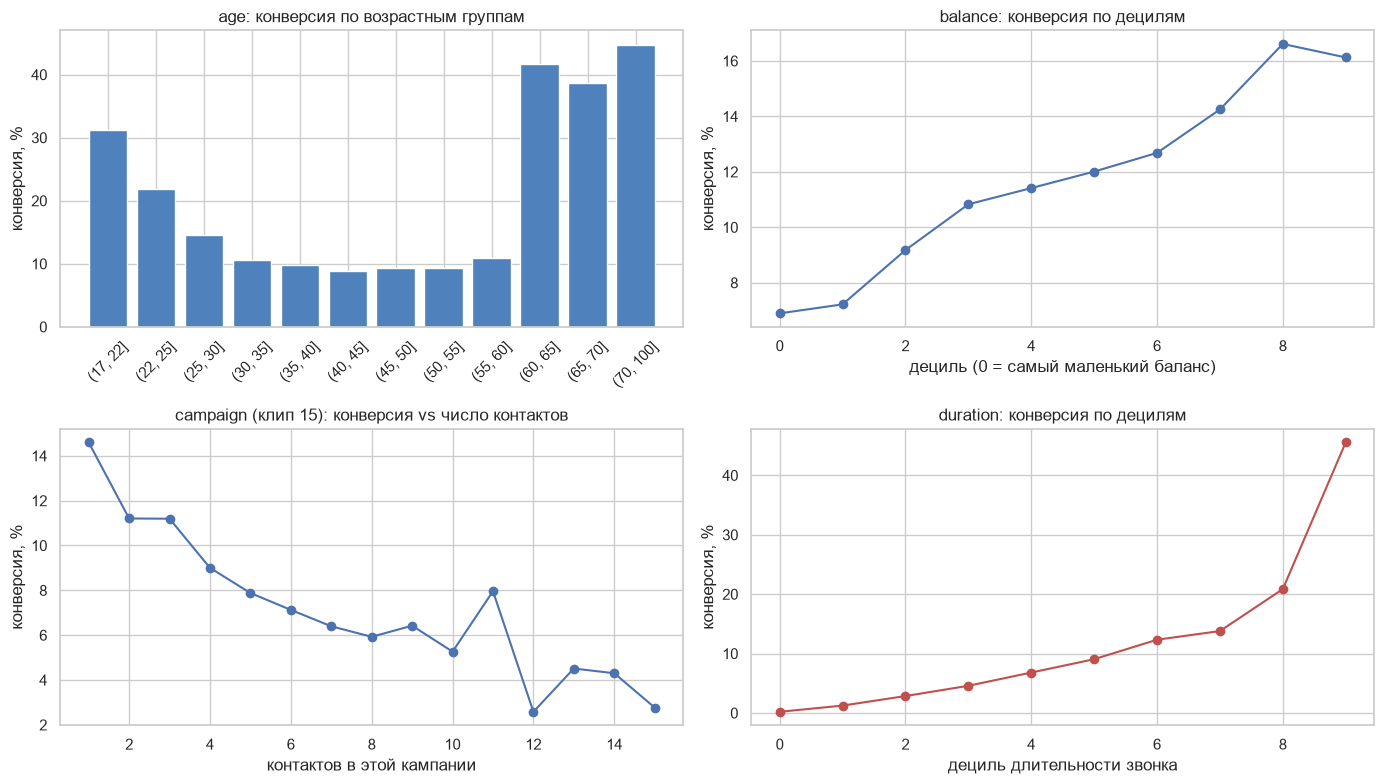

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
# age
g = df.groupby(pd.cut(df.age,[17,22,25,30,35,40,45,50,55,60,65,70,100]), observed=True).target.agg(['mean','size'])
axs[0,0].bar(g.index.astype(str), g['mean']*100, color='#4f81bd'); axs[0,0].set_title('age: конверсия по возрастным группам'); axs[0,0].tick_params(axis='x', rotation=45)
# balance deciles
g = df.groupby(pd.qcut(df.balance,10,duplicates='drop'), observed=True).target.mean()
axs[0,1].plot(range(len(g)), g.values*100, 'o-'); axs[0,1].set_title('balance: конверсия по децилям'); axs[0,1].set_xlabel('дециль (0 = самый маленький баланс)')
# campaign
g = df.groupby(df.campaign.clip(upper=15)).target.agg(['mean','size'])
axs[1,0].plot(g.index, g['mean']*100, 'o-'); axs[1,0].set_title('campaign (клип 15): конверсия vs число контактов'); axs[1,0].set_xlabel('контактов в этой кампании')
# duration deciles
g = df.groupby(pd.qcut(df.duration,10), observed=True).target.mean()
axs[1,1].plot(range(len(g)), g.values*100, 'o-', color='#c0504d'); axs[1,1].set_title('duration: конверсия по децилям'); axs[1,1].set_xlabel('дециль длительности звонка')
for a in axs.ravel(): a.set_ylabel('конверсия, %')
plt.tight_layout(); plt.show()

**Что видно:**
- **age — U-образная зависимость:** до 25 лет ≈ 24%, 60+ ≈ 42%, а в середине (30–60) всего ≈ 9–10%. Линейно возраст в модель подавать нельзя — нужны бины/сплайны или деревья. Это же объясняет, почему `student`/`retired` — лидеры по job.
- **balance — монотонный рост:** от ≈ 7% (баланс ≤ 0) до ≈ 16% (верхние децили), дальше выходит на плато. Хороши `log`-преобразование и флаг `balance<=0`.
- **campaign — убывающая:** 14.6% при 1 контакте → ~4% при 10+. «Назойливость» не помогает; после ~3–5 звонков отдача падает.
- **duration — резко растёт** (0.2% → 45.5%), но это **утечка**, см. H3.

## 5. Проверка гипотез
Смотрим конверсию по группам и проверяем, подтверждаются ли наши наблюдения.

### H3. `duration` — самый сильный признак, но он недоступен на момент решения (утечка)

In [24]:
print(df.groupby('target').duration.describe().round(0))
print('\nМедиана длительности, сек: yes =', df.loc[df.target==1,'duration'].median(), '| no =', df.loc[df.target==0,'duration'].median())

          count   mean    std  min    25%    50%    75%     max
target                                                         
0       39922.0  221.0  207.0  0.0   95.0  164.0  279.0  4918.0
1        5289.0  537.0  393.0  8.0  244.0  426.0  725.0  3881.0

Медиана длительности, сек: yes = 426.0 | no = 164.0


Звонок идёт дольше, когда клиент заинтересован, т.е. `duration` — **следствие**, а не причина. Длительность известна только *после* звонка, а предиктор нужен, чтобы решить *кого обзванивать*. Это классическая утечка (UCI прямо пишет: «для реалистичной модели признак стоит выбросить»).

### H4. Сезонность: конверсия сильно зависит от месяца, причём не из-за объёма

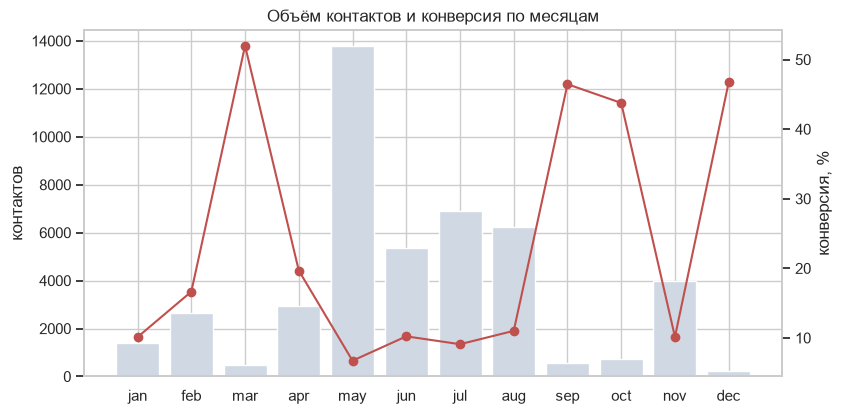

Корреляция Спирмена (объём, конверсия) по месяцам: -0.85


In [25]:
mm = df.groupby('month_num').target.agg(['mean','size']); mm.index = months
fig, ax = plt.subplots(); ax.bar(mm.index, mm['size'], color='#cfd8e3'); ax.set_ylabel('контактов')
ax2 = ax.twinx(); ax2.plot(mm.index, mm['mean']*100, 'o-', color='#c0504d'); ax2.set_ylabel('конверсия, %'); ax2.grid(False)
ax.set_title('Объём контактов и конверсия по месяцам'); plt.show()
print(f"Корреляция Спирмена (объём, конверсия) по месяцам: {mm['size'].corr(mm['mean'], method='spearman'):.2f}")

**Вывод H4 (промежуточный):** связь с месяцем сильная. Март, сентябрь, октябрь, декабрь — конверсия **44–52%**, но это крошечные объёмы (214–738 контактов); май — 30% всех контактов и всего 6.7% конверсии (корреляция Спирмена «объём ↔ конверсия» по месяцам ≈ −0.85). Проверим, не маскируется ли под месяц *год* (см. п. 2.2):

In [26]:
pv = df.pivot_table(index='month_num', columns='year', values='target', aggfunc='mean')*100
cnt = df.pivot_table(index='month_num', columns='year', values='target', aggfunc='size')
pv.index = cnt.index = months
display(pv.round(1).fillna('—').add_prefix('конв.% ').join(cnt.fillna(0).astype(int).add_prefix('n ')))

year,конв.% 2008,конв.% 2009,конв.% 2010,n 2008,n 2009,n 2010
jan,—,3.2,45.8,0,1176,227
feb,—,11.1,52.7,0,2296,353
mar,—,48.4,56.2,0,258,219
apr,—,16.6,58.9,0,2718,214
may,3.2,9.6,57.3,7957,5575,234
jun,4.5,37.5,48.8,4486,642,213
jul,6.0,36.7,54.2,6380,207,308
aug,5.5,34.2,52.3,5215,772,260
sep,—,43.6,49.2,0,282,297
oct,61.3,42.0,40.9,80,438,220


**Вывод H4: гипотеза о «чистой сезонности» не подтверждена — месяц сильно смешан с годом.** Месяцы-лидеры (`mar`, `sep`, `oct`, `dec`) встречаются почти только в 2009–2010, когда банк звонил малому, отобранному кругу и конверсия в целом была 17–52%; а `may`/`jun`/`jul`/`aug` — это в основном массовый 2008-й с ≈5%. Месяц — сильный предиктор *в этих данных*, но во многом как «прокси года/отбора клиентов». ⚠ Для честной оценки: временной split; не интерпретировать `month` как «осенью люди охотнее открывают депозиты».

### H5. Прошлый успех — главный предиктор текущего

In [27]:
t = df.groupby(df.poutcome.astype('object').fillna('no_prev')).target.agg(['mean','size'])
t['lift_vs_avg'] = t['mean']/df.target.mean(); display(t.round(3))


,mean,size,lift_vs_avg
poutcome,,,
failure,0.126,4901,1.078
no_prev,0.092,36959,0.783
other,0.167,1840,1.426
success,0.647,1511,5.533


**Вывод H5: подтверждена.** Клиенты с `success` в прошлой кампании соглашаются в **64.7%** случаев (lift ≈ 5.5×), при этом их всего 1511 (3.3%). Работает как мощный, но «узкий» признак: хорошо для ранжирования верхушки, мало влияет на общую картину.

### H6. Долговая нагрузка (`housing`, `loan`) снижает конверсию — и это не просто эффект возраста
Проверим, сохраняется ли эффект ипотеки внутри возрастных групп (иначе это «подмена» возрастом).

In [28]:
age_bin = pd.cut(df.age, [17,30,40,50,60,100], labels=['<=30','31-40','41-50','51-60','60+'])
pt = df.pivot_table(index=age_bin, columns='housing', values='target', aggfunc='mean', observed=True)*100
pt['разница'] = pt['no'] - pt['yes']; display(pt.round(1))

housing,no,yes,разница
age,,,
<=30,25.7,9.4,16.3
31-40,14.7,7.7,7.0
41-50,12.0,6.8,5.2
51-60,12.7,6.4,6.2
60+,41.8,48.8,-7.0


**Вывод H6: подтверждена для клиентов до 60 лет, в 60+ эффект обратный.** В группах ≤30 / 31–40 / 41–50 / 51–60 клиенты без ипотеки соглашаются чаще на 16 / 7 / 5 / 6 п.п. — эффект самостоятельный, а не следствие возраста. В группе 60+ картина перевёрнута (41.8% без ипотеки vs 48.8% с ипотекой, но выборка там мала и состоит в основном из пенсионеров — не делаем вывода). Значит, взаимодействие `age × housing` стоит учесть (деревья ловят это сами). `housing`, `loan` и `n_loans` — полезные фичи.

### H7. Баланс и возраст/работа коррелируют между собой (мультиколлинеарность и подмена эффектов)

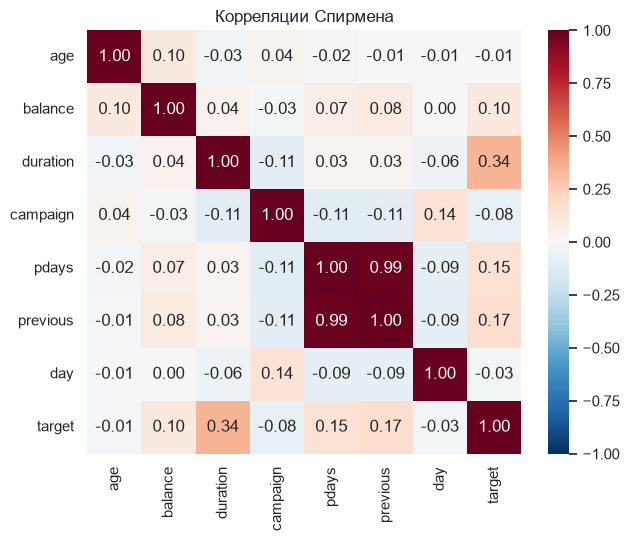

In [29]:
numcols = ['age','balance','duration','campaign','pdays','previous','day','target']
corr = df[numcols].corr(method='spearman')
plt.figure(figsize=(7,5.5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1); plt.title('Корреляции Спирмена'); plt.show()

**Вывод H7:** числовые признаки почти не коррелируют друг с другом (мультиколлинеарность не проблема), кроме естественной пары `pdays`–`previous` (оба описывают прошлые контакты, и оба «сломаны» значением `pdays=-1`). С таргетом линейная связь слабая, у `duration` — самая сильная. Линейные корреляции **недооценивают** U-образный `age` — его смотрим по группам (п. 4.1).

## 6. Идеи для фичей
| Фича | Как считать | Зачем / обоснование |
|---|---|---|
| `prev_contacted` | `pdays != -1` (или `previous > 0`) | Явный флаг вместо «сломанного» `pdays=-1` (H1) |
| `pdays_clean` | `pdays` с `-1 → NaN` (+ бины: <90, 90–200, 200+ дней) | Для моделей на числах; «давность» контакта |
| `poutcome_filled` | `NaN → 'no_prev'` | Осмысленная категория (H1) |
| `contact_unknown` | `contact.isna()` | Прокси периода май–июнь 2008 (98% NaN — 2008 год, H2b); на временной валидации работать не будет |
| `year`, `quarter`, `date`, `t_index` | Реконструкция из порядка строк (п. 2.2) | Дрейф (5% → 17% → 52%); в модель на «будущее» год подавать нельзя — только для разбиения по времени |
| `month_conv` (таргет-энкодинг) | Среднее таргета по месяцу, **только на train/внутри фолда** | Сильный сезонный сигнал (H4); риск утечки без CV-энкодинга |
| `age_bin` / `age_u = (age-45)^2` | Бины или квадрат | U-образность (п. 4.1) |
| `is_student_or_retired` | `job in {student, retired}` | Лидеры конверсии, компактная фича |
| `balance_log`, `balance_neg` | `sign(b)*log1p(\|b\|)`, `balance<=0` | Скошенность и плато (п. 2.3, 4.1) |
| `n_loans` | `(housing=='yes') + (loan=='yes') + (default=='yes')` | Долговая нагрузка (H6) |
| `campaign_clip`, `campaign_gt3` | `min(campaign, 10)`, `campaign>3` | Убывающая отдача, хвосты |
| `prev_success` | `poutcome=='success'` | Самый сильный бинарный сигнал (H5) |
| `edu_job` | Комбинация `job × education` | Возможное взаимодействие, смотреть на редкость групп |
| `duration_per_contact` | `duration / campaign` | ⚠ **Только** для эксперимента с утечкой |

## 7. Итоговые выводы для построения предиктора

1. **Таргет** несбалансирован (≈11.7% `yes`) → метрики ROC-AUC / PR-AUC / lift@k, стратификация, `class_weight` или подбор порога.
2. **`duration` — утечка**: исключаем из боевой модели; можно оставить как «верхнюю границу» эксперимент.
3. **Пропуски осмысленные**: `poutcome=NaN` ⇔ нет прошлой кампании (≈82%); `contact=NaN` — это почти целиком май–июнь 2008 (H2b), т.е. прокси периода, а не свойство клиента. Заполняем категориями + флаги, а не модой.
4. **`pdays=-1` — маркер**, а не число; `pdays` и `previous` связаны полностью.
5. **`day_of_week` — на самом деле день месяца**; данные упорядочены по времени (2008–2010) → дата восстановима. Конверсия по годам **5% → 17% → 52%**, поэтому **валидировать нужно по времени** (train — ранние даты, test — поздние).
6. **Нелинейности**: `age` (U-образно), `balance` (плато), `campaign` (убывает) → бины/деревья/бустинг; для линейных моделей — трансформации.
7. **Самые заметные сигналы по конверсии** (без `duration`): `poutcome`/`pdays`, `month` (но это во многом прокси года), `balance`, `contact`, `age`, `housing`/`loan`, `job`.
8. **Ограничения:** 2008–2010 (кризис), смещение отбора клиентов по месяцам, редкие категории (`default=yes`, `success`) → осторожно с переобучением на них.

**Следующие шаги:** собрать пайплайн препроцессинга (импутация-флаги + кодирование), временную валидацию, baseline (LogReg) и бустинг; сравнить с/без `duration`; подобрать порог под бизнес-метрику.